In [43]:
'''
#. Question 1:
 
A retail store wants to identify customers who make frequent purchases. Given the dataset below, write a code to:
1.	Group customers by their IDs.
2.	Calculate the total number of purchases per customer.
3.	Identify the top 3 frequent customers.
'''
import pandas as pd

data = {'Customer_ID': [101, 102, 103, 101, 104, 102, 101, 105, 102, 103],
        'Purchase_Amount': [200, 150, 180, 220, 300, 200, 100, 400, 250, 300]}

df = pd.DataFrame(data)

group_customer = df.groupby("Customer_ID", as_index=False)["Purchase_Amount"].sum()
print("Total Purchases per Customer:\n",group_customer)

top3_customer = group_customer.sort_values("Purchase_Amount",ascending=False).head(3)
print("\nTop 3 Frequent Customers:\n",top3_customer)

Total Purchases per Customer:
    Customer_ID  Purchase_Amount
0          101              520
1          102              600
2          103              480
3          104              300
4          105              400

Top 3 Frequent Customers:
    Customer_ID  Purchase_Amount
1          102              600
0          101              520
2          103              480


In [105]:
'''
Question 2:
A company tracks the daily sales of a product over a month. You are tasked with identifying any abnormal sales data using the IQR (Interquartile Range) method.
'''
import pandas as pd
import numpy as np

data = {'Day': range(1, 31),
        'Sales': [25, 30, 28, 45, 55, 60, 22, 80, 95, 120,
                  33, 29, 27, 35, 40, 50, 85, 110, 105, 92,
                  30, 34, 31, 33, 36, 42, 44, 48, 90, 200]}
df = pd.DataFrame(data)
Q1, Q3 = np.percentile(df['Sales'],[25,75])
IQR = Q3 - Q1
print("Q1:",Q1, "Q3:", Q3, "IQR:",IQR)
lower_band = Q1 - 1.5 * IQR
upper_band = Q3 + 1.5 * IQR
print("\nLower Bound:",lower_band, "Upper Bound:", upper_band)
outliers = df[(df['Sales'] < lower_band) | (df['Sales'] > upper_band)]
print("\nOutliers Detected:\n",outliers)
median_value = np.median(df['Sales'])
print("\nMedian Value:",median_value)
df.loc[(df['Sales'] < lower_band) | (df['Sales'] > upper_band)] = median_value
print("\nCleaned DataFrame:\n", df)

Q1: 31.5 Q3: 83.75 IQR: 52.25

Lower Bound: -46.875 Upper Bound: 162.125

Outliers Detected:
     Day  Sales
29   30    200

Median Value: 43.0

Cleaned DataFrame:
     Day  Sales
0     1     25
1     2     30
2     3     28
3     4     45
4     5     55
5     6     60
6     7     22
7     8     80
8     9     95
9    10    120
10   11     33
11   12     29
12   13     27
13   14     35
14   15     40
15   16     50
16   17     85
17   18    110
18   19    105
19   20     92
20   21     30
21   22     34
22   23     31
23   24     33
24   25     36
25   26     42
26   27     44
27   28     48
28   29     90
29   43     43


In [111]:
'''
Question 3:
 
A pharmaceutical company is testing the effectiveness of a new drug to reduce blood pressure. Two groups of patients were selected:
Group 1 (Treatment): Received the drug
Group 2 (Control): Received a placebo
The company wants to check if there is a significant difference in the blood pressure levels between the two groups using an Independent T-Test.
'''

import pandas as pd
import numpy as np
from scipy import stats

data = {'Group': ['Treatment']*10 + ['Control']*10,
        'Blood_Pressure': [120, 115, 118, 123, 122, 119, 124, 117, 116, 121,
                            130, 135, 140, 138, 142, 136, 139, 134, 137, 141]}

df = pd.DataFrame(data)

Treatment = df[df['Group'] == 'Treatment']['Blood_Pressure']
Control = df[df['Group'] == 'Control']['Blood_Pressure']

t_stat,p_value = stats.ttest_ind(Treatment, Control)

print("T-Statistic:",t_stat)
print("P-Value:",p_value)
alpha = 0.05

H0 = "Reject the Null Hypothesis: The drug has a significant effect." if p_value < alpha else "No significant difference: The drug effect is not proven."
print(H0)



T-Statistic: -11.870553692962726
P-Value: 6.008066605173383e-10
Reject the Null Hypothesis: The drug has a significant effect.


In [133]:
'''
Question 4:
GlobalMart is a large retailer conducting advertisement campaigns in different regions. The company spends money on two types of advertisements: TV Ads and Social Media Ads
They want to analyze how these ads influence their sales.
Your task is to calculate the Covariance and Correlation to determine which type of ad has a stronger impact on sales.
'''
import pandas as pd
import numpy as np

data = {'Region': ['North', 'South', 'East', 'West', 'Central'],
        'TV_Ad_Budget': [200,300,400,500,600],
        'Social_Media_Budget':[150,250,300,450,500],
        'Sales':[20,35,50,60,80]}
#Covarience
cov_matrix_1 = np.cov(df['TV_Ad_Budget'], df['Sales'])
cov_matrix_2 = np.cov(df['Social_Media_Budget'], df['Sales'])
cov_value_1 = cov_matrix_1[0, 1]
cov_value_2 = cov_matrix_2[0, 1]
print("Covariance (TV vs Sales):",cov_value_1)
print("Covariance (Social Media vs Sales):",cov_value_2)

#.Correlation
cor_matrix_1 = np.corrcoef(df['TV_Ad_Budget'], df['Sales'])
cor_matrix_2 = np.corrcoef(df['Social_Media_Budget'], df['Sales'])
cor_value_1 = cor_matrix_1[0, 1]
cor_value_2 = cor_matrix_2[0, 1]
print("Correlation (TV vs Sales):",cor_value_1)
print("Correlation (Social Media vs Sales):",cor_value_2)
print("TV Ads have a stronger impact on Sales." if cor_value_1 > cor_value_2 else "Social Media have a stronger impact on Sales.")


Covariance (TV vs Sales): 3625.0
Covariance (Social Media vs Sales): 3225.0
Correlation (TV vs Sales): 0.9958640886279954
Correlation (Social Media vs Sales): 0.9724846021568381
TV Ads have a stronger impact on Sales.


Mean Delivery Time: 65.0625
Standard Deviation of Delivery Time: 41.718504212759115


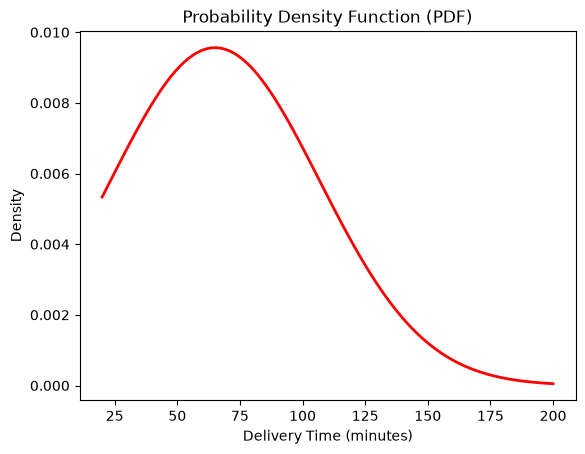

In [144]:
'''
Question 5:
A company tracks the delivery time (in minutes) for its online orders. You are given the delivery times for 50 orders.
●	Calculate the mean and standard deviation of the delivery times.
●	Plot the Probability Density Function (PDF) to visualize the distribution.
'''
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

dataset = [25, 30, 28, 45, 55, 60, 22, 80, 95, 120, 33, 29, 27, 
           35, 40, 50, 85, 110, 105, 92, 30, 34, 31, 33, 36, 42, 
           44, 48, 90, 200, 20, 25, 27, 32, 38, 41, 47, 58, 62, 
           77, 80, 84, 90, 110, 123, 145, 150, 160]

mean_val = np.mean(dataset)
print("Mean Delivery Time:",mean_val)
std_val = np.std(dataset)
print("Standard Deviation of Delivery Time:",std_val)
x = np.linspace(min(dataset), max(dataset), 100)
pdf = norm.pdf(x, mean_val, std_val)
plt.plot(x, pdf, 'r-', linewidth=2, label='PDF')
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Density")
plt.title("Probability Density Function (PDF)")
plt.show()